<a href="https://colab.research.google.com/github/SergeiVKalinin/Paper_Notebooks/blob/main/VAE_Walls/Supplement_02_Symmetry_Folding_Controls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Supplementary 02 — symmetry, folding, and independent neural controls

This notebook checks the dimensionality and learning-trajectory mechanisms discussed in the supplement. The first two sections calculate simple **analytical or synthetic-model** controls; the last section performs a fresh neural experiment.

**Important source limitation:** historical supplementary Figures S5 and S6 were supplied as rendered figures, without complete original training records. The experiment below is new and independently executable; it is not claimed to recover the historical pixel arrays or identical optimization history. The latest streamlined supplement may not include a standalone S6 figure. Only PNGs are saved.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# All user-visible output is PNG; nothing is cached or exported in other formats.
OUTPUT = Path('/content') if Path('/content').exists() else Path.cwd()
FAST_MODE = True       # False: use the longer, publication-scale calculations.
DPI = 180 if FAST_MODE else 300

def save_panel(fig, filename):
    fig.savefig(OUTPUT / filename, dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved', OUTPUT / filename)

from scipy import optimize
import torch
from torch import nn
from torch.nn import functional as F
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## S3 control — quotient-orbit winding and continuity

For an ideal representation of an exact n-fold symmetric object, the quotient angle `n*theta` winds `n` times when physical orientation advances by one full revolution. This shows **permitted topology under a faithful quotient representation**, not a theorem that every trained VAE learns that winding.

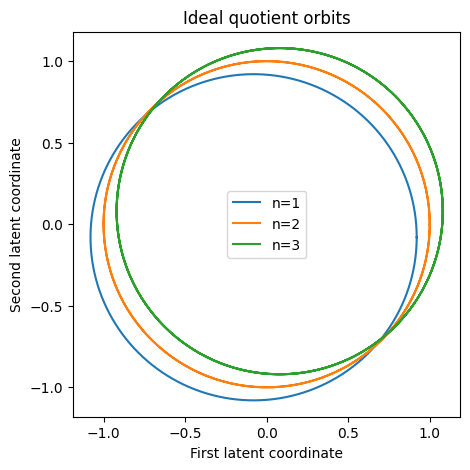

Saved /content/FigS03_quotient_orbits.png


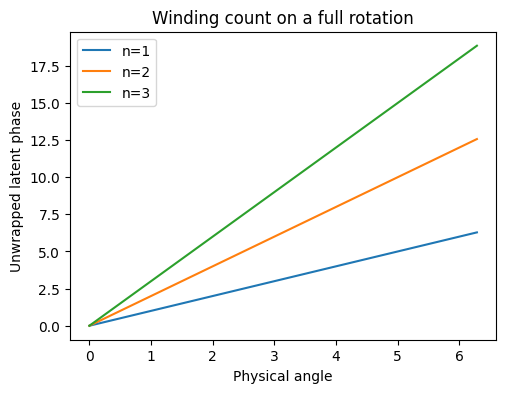

Saved /content/FigS03_winding_numbers.png


In [2]:
theta=np.linspace(0,2*np.pi,500)
fig,ax=plt.subplots(figsize=(5,5))
for n in [1,2,3]:
    x=np.cos(n*theta);y=np.sin(n*theta)
    ax.plot(x+.08*(n-2),y+.08*(n-2),label=f'n={n}')
ax.set(xlabel='First latent coordinate',ylabel='Second latent coordinate',title='Ideal quotient orbits')
ax.axis('equal');ax.legend()
save_panel(fig,'FigS03_quotient_orbits.png')
fig,ax=plt.subplots(figsize=(5.5,4))
for n in [1,2,3]:ax.plot(theta,np.unwrap(np.angle(np.exp(1j*n*theta))),label=f'n={n}')
ax.set(xlabel='Physical angle',ylabel='Unwrapped latent phase',title='Winding count on a full rotation')
ax.legend();save_panel(fig,'FigS03_winding_numbers.png')

## S4 — reduced fold law and its assumptions

Quantizing a secondary continuous factor into `N` levels produces a distortion cost proportional to `A/N²`, balanced against an information cost `ln N`. In this restricted model, `N` grows as the square root of `A`. We compare discrete alternatives explicitly and display example serpentine maps. This is **not evidence that an amortized neural VAE finds these folds**.

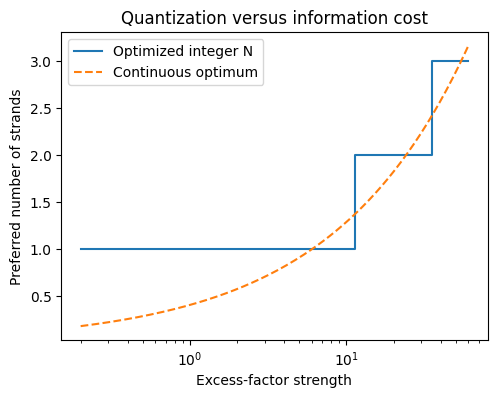

Saved /content/FigS04_a_strand_count.png


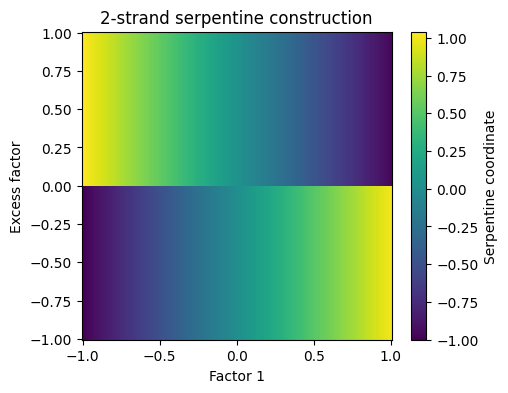

Saved /content/FigS04_b_2_strand_map.png


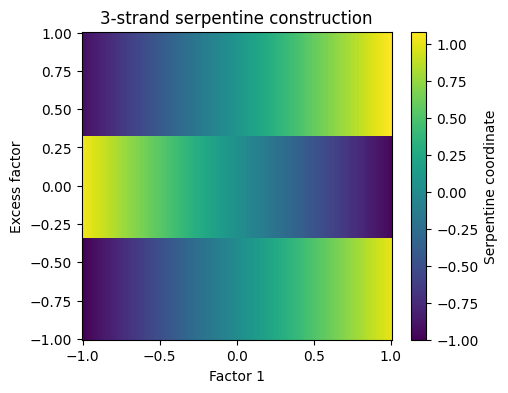

Saved /content/FigS04_b_3_strand_map.png


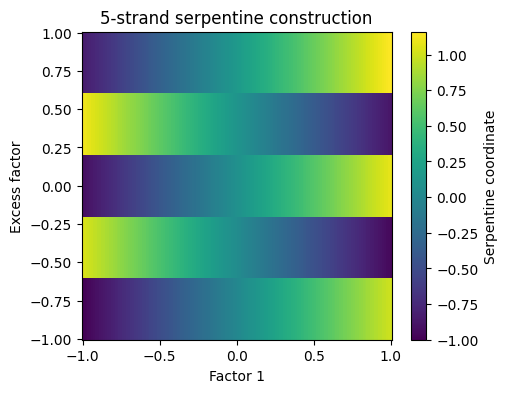

Saved /content/FigS04_b_5_strand_map.png


In [3]:
# A is the dimensionless strength of the excess factor; a coefficient is fixed by our toy model.
strength=np.geomspace(.2,60,180)
Nrange=np.arange(1,13)
loss=np.array([np.log(Nrange)+a/(12*Nrange**2) for a in strength])
bestN=Nrange[loss.argmin(axis=1)]
fig,ax=plt.subplots(figsize=(5.5,4))
ax.semilogx(strength,bestN,drawstyle='steps-mid',label='Optimized integer N')
ax.semilogx(strength,np.sqrt(strength/6),'--',label='Continuous optimum')
ax.set(xlabel='Excess-factor strength',ylabel='Preferred number of strands',title='Quantization versus information cost')
ax.legend();save_panel(fig,'FigS04_a_strand_count.png')

# Maps are computed from their displayed, explicitly defined serpentine coordinate rule.
u=np.linspace(-1,1,160);v=np.linspace(-1,1,160)
U,V=np.meshgrid(u,v)
for n in [2,3,5]:
    level=np.clip(np.floor((V+1)*n/2).astype(int),0,n-1)
    orient=np.where(level%2==0,U,-U)
    encoded=orient + 0.04*level
    fig,ax=plt.subplots(figsize=(5,4))
    im=ax.pcolormesh(U,V,encoded,shading='auto',cmap='viridis')
    fig.colorbar(im,ax=ax,label='Serpentine coordinate')
    ax.set(xlabel='Factor 1',ylabel='Excess factor',title=f'{n}-strand serpentine construction')
    save_panel(fig,f'FigS04_b_{n}_strand_map.png')

## S5 control — fresh amortized VAE on synthetic three-factor data

We train a 2D VAE on a 64-dimensional linear embedding of **three independent uniform factors**. The question is whether the third factor gets folded, weakly represented, or suppressed. A negative result in a limited run does not prove the absence of other optimization minima.

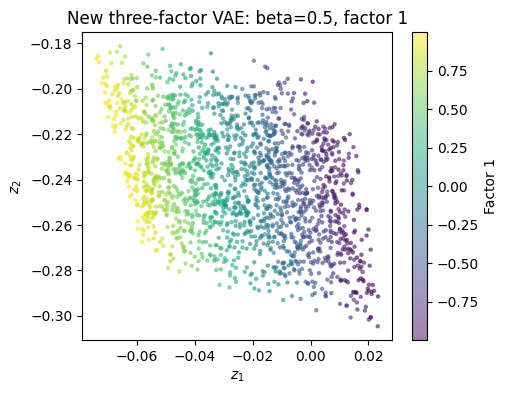

Saved /content/FigS05_beta0.5_factor1.png


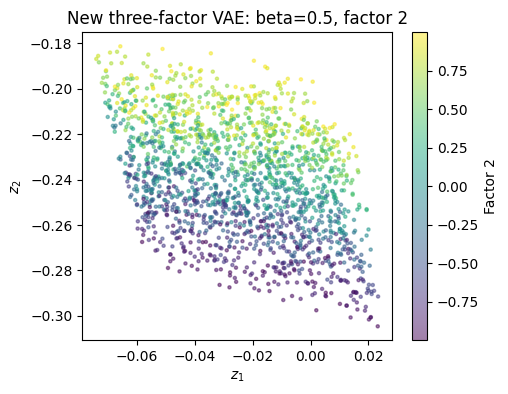

Saved /content/FigS05_beta0.5_factor2.png


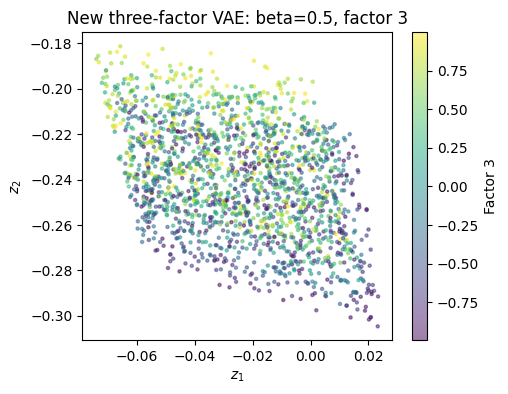

Saved /content/FigS05_beta0.5_factor3.png


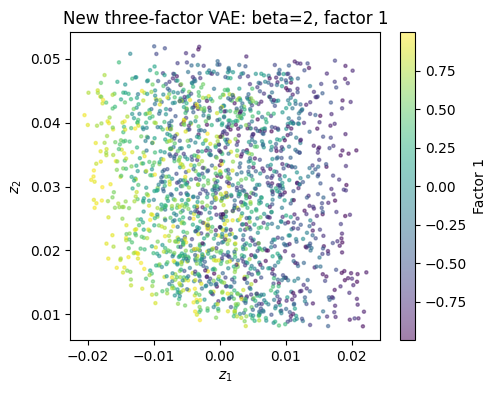

Saved /content/FigS05_beta2_factor1.png


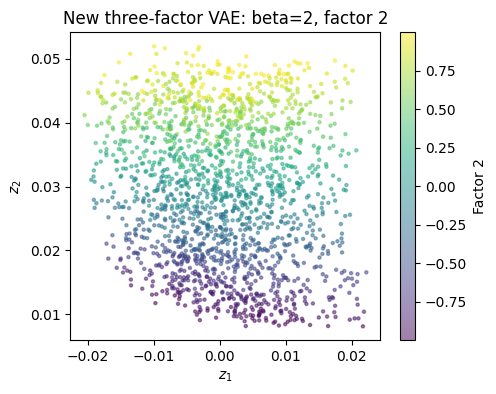

Saved /content/FigS05_beta2_factor2.png


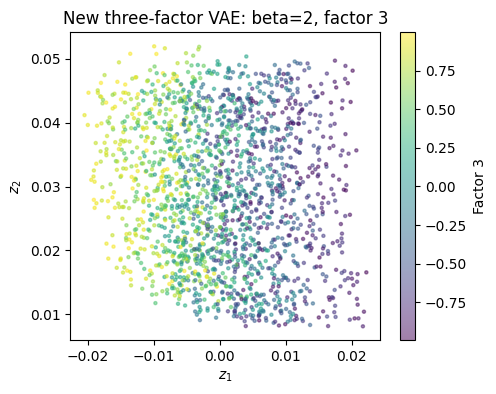

Saved /content/FigS05_beta2_factor3.png


In [4]:
rng=np.random.default_rng(17)
n=1800 if FAST_MODE else 10000
factors=rng.uniform(-1,1,(n,3)).astype('float32')
Q,_=np.linalg.qr(rng.normal(size=(64,3)))
X=(factors@Q.T).astype('float32')
X=(X-X.min())/(X.max()-X.min())

class SmallVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(64,128),nn.Tanh())
        self.mu=nn.Linear(128,2);self.logvar=nn.Linear(128,2)
        self.decoder=nn.Sequential(nn.Linear(2,128),nn.Tanh(),nn.Linear(128,64))
    def forward(self,x):
        h=self.encoder(x);m=self.mu(h);lv=self.logvar(h).clamp(-10,8)
        z=m+torch.randn_like(m)*torch.exp(.5*lv)
        return self.decoder(z),m,lv

for beta in ([.5,2.] if FAST_MODE else [.5,2.,8.]):
    torch.manual_seed(18)
    model=SmallVAE().to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=.001)
    data=torch.tensor(X,device=DEVICE)
    for epoch in range(5 if FAST_MODE else 50):
        for ids in torch.randperm(n,device=DEVICE).split(128):
            recon,mu,lv=model(data[ids]);target=data[ids]
            rec=((recon-target)**2).sum()/len(ids)
            kl=(-.5*(1+lv-mu.square()-lv.exp()).sum())/len(ids)
            opt.zero_grad();(rec+beta*kl).backward();opt.step()
    model.eval()
    with torch.no_grad():z=model.mu(model.encoder(data)).cpu().numpy()
    for k in range(3):
        fig,ax=plt.subplots(figsize=(5,4))
        im=ax.scatter(z[:,0],z[:,1],c=factors[:,k],s=5,cmap='viridis',alpha=.5)
        fig.colorbar(im,ax=ax,label=f'Factor {k+1}')
        ax.set(xlabel='$z_1$',ylabel='$z_2$',title=f'New three-factor VAE: beta={beta:g}, factor {k+1}')
        save_panel(fig,f'FigS05_beta{beta:g}_factor{k+1}.png')